<a href="https://colab.research.google.com/github/Natashacap/FIT3181-Deep-learning/blob/main/Assignment01_Part2_solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <font color="#0b486b">  FIT3181: Deep Learning (2026)</font>
***
*CE/Lecturer (Clayton):* **Dr [Trung Le](mailto:trunglm@monash.edu)** <br/>
*Lecturer (Clayton):* **Dr [Binh Nguyen](mailto:binh.nguyen1@monash.edu)** <br/>
*Lecturer (Malaysia):*  **Dr [Arghya Pal](mailto:arghya.pal@monash.edu)**, **Dr [Sailaja Rajanala](mailto:sailaja.rajanala@monash.edu)**, **Dr [Sicily Fung Fung Ting](mailto:ting.fung@monash.edu)** <br/>
*Head Tutor (Clayton):* **Mr [Minh Vo](mailto:minh.vo1@monash.edu)** (FIT3181), **Dr [Ruda Nie H](mailto:rudanie.h@monash.edu)** (FIT5215)

Faculty of Information Technology, Monash University, Australia
***

## Assignment 1 - Part 2
### Deep Neural Networks (DNN)
***

# <font color="#0b486b">  Student Information</font>
***
Surname: **[Huang]**  <br/>
Firstname: **[Shijia ]**    <br/>
Student ID: **[35615028 ]**    <br/>
Email: **[shua0169@student.monash.edu ]**    <br/>
Your tutorial time: **[Monday 12pm ]**    <br/>
***

# <font color="#0b486b">Deep Neural Networks</font>
### Due: <font color="red">11:55pm Sunday, 13 September 2026</font>  (Sunday)

#### <font color="red">Important note:</font> This is an **individual** assignment. It contributes **25%** to your final mark. Read the assignment instructions carefully.

## <font color="#0b486b">What to submit</font>

This assignment is to be completed individually and submitted to Moodle unit site. **By the due date, you are required to submit one  <font color="red; font-weight:bold">single zip file, named xxx_assignment01_solution.zip</font> where `xxx` is your student ID, to the corresponding Assignment (Dropbox) in Moodle**. You can use Google Colab to do Assigmnent 1 but you need to save it to an `*.ipynb` file to submit to the unit Moodle.

**More importantly, if you use Google Colab to do this assignment, you need to first make a copy of this notebook on your Google drive**.

***For example, if your student ID is <font color="red; font-weight:bold">123456</font>, then gather all of your assignment solution to folder, create a zip file named <font color="red; font-weight:bold">123456_assignment01_solution.zip</font> and submit this file.***

Within this zip folder, you **must** submit the following files:

1.	**Assignment01_solution.ipynb**:  this is your Python notebook solution source file.

2.	**Assignment01_output.html** or **Assignment01_output.pdf**: this is the output of your Python notebook solution *exported* in html or pdf format.

3.	Any **extra files or folder** needed to complete your assignment (e.g., images used in your answers).

Since the notebook is quite big to load and work together, one recommended option is to split solution into three parts and work on them seperately. In that case, replace **Assignment01_solution.ipynb** by three notebooks: **Assignment01_Part1_solution.ipynb**, **Assignment01_Part2_solution.ipynb** and **Assignment01_Part3_solution.ipynb**

**You can run your codes on Google Colab. In this case, you have to make a copy of your Google colab notebook including the traces and progresses of model training before submitting.**



## <font color="#0b486b">Part 2: Deep Neural Networks (DNN) </font>
<div style="text-align: right"><font color="red; font-weight:bold">[Total marks for this part: 25 points]</font></div>

The second part of this assignment is to demonstrate your basis knowledge in deep learning that you have acquired from the lectures and tutorials materials. Most of the contents in this assignment are drawn from **the tutorials covered from weeks 1 to 2**. Going through these materials before attempting this assignment is highly recommended.

In the second part of this assignment, you are going to work with the FashionMNIST dataset for the image recognition task. It has the exact same format as MNIST (70,000 grayscale images of 28 × 28 pixels each with 10 classes), but the images represent fashion items rather than handwritten digits, so each class is more diverse, and the problem is significantly more challenging than MNIST.

In [2]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(1234)

**Load the Fashion MNIST using `torchvision`**

In [3]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

train_dataset_orgin = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

print(train_dataset_orgin.data.shape, train_dataset_orgin.targets.shape)
print(test_dataset.data.shape, test_dataset.targets.shape)

# Flatten the data
train_dataset_orgin.data = train_dataset_orgin.data.reshape(-1, 28*28)
test_dataset.data = test_dataset.data.reshape(-1, 28*28)

print(train_dataset_orgin.data.shape, train_dataset_orgin.targets.shape)
print(test_dataset.data.shape, test_dataset.targets.shape)

N = len(train_dataset_orgin)
print(f"Number of training samples: {N}")
N_train = int(0.9*N)
N_val = N - N_train
print(f"Number of training samples: {N_train}")
print(f"Number of validation samples: {N_val}")

train_dataset, val_dataset = torch.utils.data.random_split(train_dataset_orgin, [N_train, N_val])


print(len(train_dataset))
print(len(val_dataset))


train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=1000, shuffle=False)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 201kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 2.85MB/s]

torch.Size([60000, 28, 28]) torch.Size([60000])
torch.Size([10000, 28, 28]) torch.Size([10000])
torch.Size([60000, 784]) torch.Size([60000])
torch.Size([10000, 784]) torch.Size([10000])
Number of training samples: 60000
Number of training samples: 54000
Number of validation samples: 6000
54000
6000


In [4]:
# ============================================================
# Shared Setup for Part 2
# Run this cell again if the Colab runtime is restarted
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


# ------------------------------------------------------------
# Feed-forward neural network used in Questions 2.2 - 2.5
# ------------------------------------------------------------
class FashionFFN(nn.Module):

    def __init__(self, n1=40, n2=30, activation="relu"):
        super().__init__()

        if activation == "relu":
            act1 = nn.ReLU()
            act2 = nn.ReLU()

        elif activation == "sigmoid":
            act1 = nn.Sigmoid()
            act2 = nn.Sigmoid()

        elif activation == "tanh":
            act1 = nn.Tanh()
            act2 = nn.Tanh()

        else:
            raise ValueError("Unknown activation function")

        self.network = nn.Sequential(
            nn.Linear(784, n1),
            act1,
            nn.Linear(n1, n2),
            act2,
            nn.Linear(n2, 10)
        )


    def forward(self, x):

        # Flatten each FashionMNIST image to 784 values
        x = x.view(x.size(0), -1).float()

        return self.network(x)


# ------------------------------------------------------------
# Evaluation function
# ------------------------------------------------------------
def evaluate_model(model, data_loader, criterion):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for x, y in data_loader:

            x = x.to(device)
            y = y.to(device)

            outputs = model(x)

            loss = criterion(
                outputs,
                y
            )

            total_loss += (
                loss.item() *
                y.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            correct += (
                predictions == y
            ).sum().item()

            total += y.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


# ------------------------------------------------------------
# Quick check
# ------------------------------------------------------------
print("FashionFFN loaded:", "FashionFFN" in globals())
print("evaluate_model loaded:", "evaluate_model" in globals())
print("train_loader loaded:", "train_loader" in globals())
print("val_loader loaded:", "val_loader" in globals())
print("test_loader loaded:", "test_loader" in globals())

Using device: cpu
FashionFFN loaded: True
evaluate_model loaded: True
train_loader loaded: True
val_loader loaded: True
test_loader loaded: True


####  <font color="red">**Question 2.1:**</font> Write the code to visualize a mini-batch in `train_loader` including its images and labels.

<div style="text-align: right"> <font color="red">[5 points]</font> </div>

Mini-batch image shape: torch.Size([64, 1, 784, 1])
Mini-batch label shape: torch.Size([64])


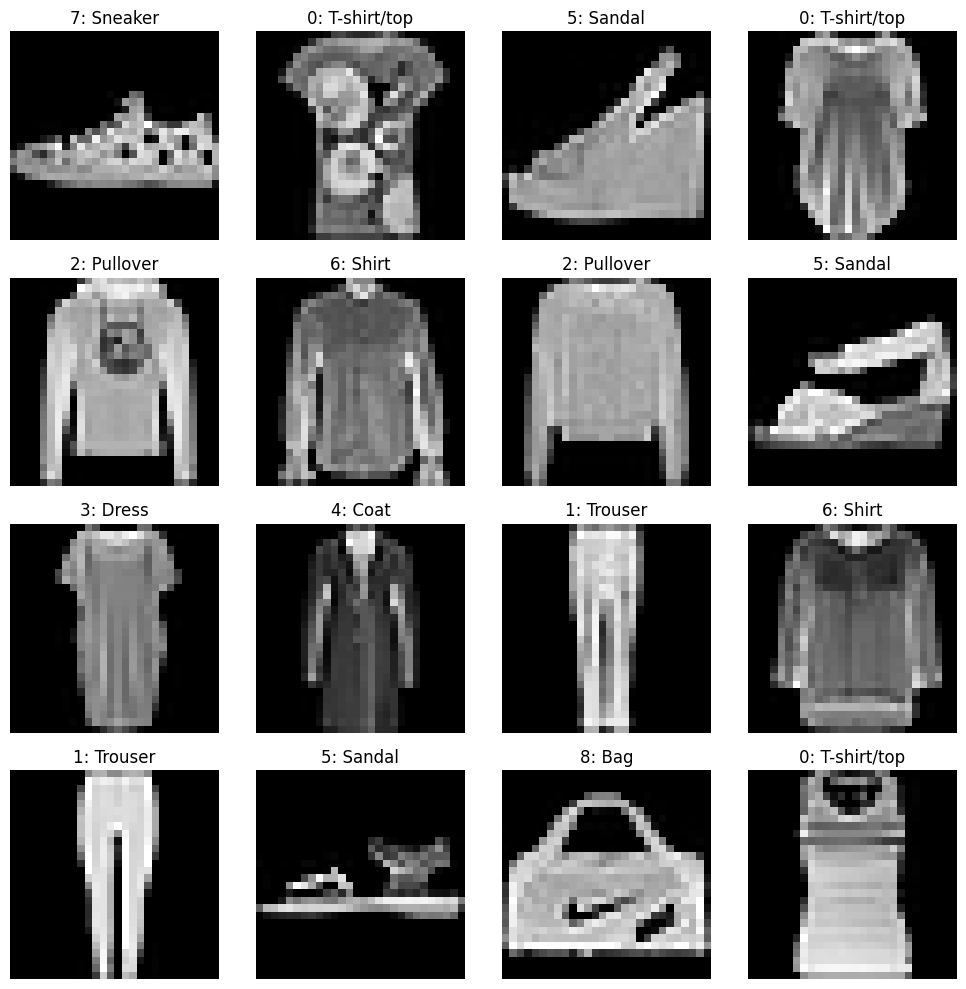

In [5]:
import matplotlib.pyplot as plt

# FashionMNIST class names
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Get one mini-batch from the training loader
images, labels = next(iter(train_loader))

print("Mini-batch image shape:", images.shape)
print("Mini-batch label shape:", labels.shape)

# Display the first 16 images from the mini-batch
plt.figure(figsize=(10, 10))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    # Reshape the flattened image back to 28 x 28
    image = images[i].reshape(28, 28)

    # Reverse the normalization from [-1, 1] to [0, 1]
    image = image * 0.5 + 0.5

    plt.imshow(image, cmap="gray")
    plt.title(f"{labels[i].item()}: {class_names[labels[i].item()]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


The mini-batch contains 64 FashionMNIST samples.  
Each flattened sample is reshaped back to $28\times28$ for visualization, and the corresponding class label is shown above each image.

####<font color="red">**Question 2.2:**</font> Write the code for the feed-forward neural net using PyTorch

<div style="text-align: right"> <font color="red">[5 points]</font> </div>

We now develop a feed-forward neural network with the architecture $784 \rightarrow 40(ReLU) \rightarrow 30(ReLU) \rightarrow 10(softmax)$. You can choose your own way to implement your network and an optimizer of interest. You should train model in $50$ epochs and evaluate the trained model on the test set.

In [6]:
import torch.nn as nn
import torch.optim as optim


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


# Feed-forward neural network
class FashionFFN(nn.Module):
    def __init__(self, n1=40, n2=30, activation="relu"):
        super().__init__()

        if activation == "relu":
            act1 = nn.ReLU()
            act2 = nn.ReLU()
        elif activation == "sigmoid":
            act1 = nn.Sigmoid()
            act2 = nn.Sigmoid()
        elif activation == "tanh":
            act1 = nn.Tanh()
            act2 = nn.Tanh()
        else:
            raise ValueError("Unknown activation function")

        self.network = nn.Sequential(
            nn.Linear(784, n1),
            act1,
            nn.Linear(n1, n2),
            act2,
            nn.Linear(n2, 10)
        )

    def forward(self, x):
        # Make sure each image is represented by 784 values
        x = x.view(x.size(0), -1).float()
        return self.network(x)


# Function for evaluating accuracy and loss
def evaluate_model(model, data_loader, criterion):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in data_loader:
            x = x.to(device)
            y = y.to(device)

            outputs = model(x)
            loss = criterion(outputs, y)

            total_loss += loss.item() * y.size(0)

            predictions = torch.argmax(outputs, dim=1)
            correct += (predictions == y).sum().item()
            total += y.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


# Build the required model
model_q22 = FashionFFN(
    n1=40,
    n2=30,
    activation="relu"
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_q22.parameters(), lr=0.001)

num_epochs = 50


# Training
for epoch in range(num_epochs):
    model_q22.train()

    running_loss = 0.0

    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        outputs = model_q22(x)
        loss = criterion(outputs, y)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * y.size(0)

    train_loss = running_loss / len(train_loader.dataset)

    val_loss, val_acc = evaluate_model(
        model_q22,
        val_loader,
        criterion
    )

    print(
        f"Epoch {epoch+1:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}%"
    )


# Final evaluation on the test set
test_loss_q22, test_acc_q22 = evaluate_model(
    model_q22,
    test_loader,
    criterion
)

print("\nFinal Test Results")
print(f"Test Loss: {test_loss_q22:.4f}")
print(f"Test Accuracy: {test_acc_q22*100:.2f}%")



Using device: cpu
Epoch 01/50 | Train Loss: 0.5872 | Val Loss: 0.4908 | Val Acc: 82.30%
Epoch 02/50 | Train Loss: 0.4127 | Val Loss: 0.4347 | Val Acc: 84.42%
Epoch 03/50 | Train Loss: 0.3771 | Val Loss: 0.4202 | Val Acc: 85.00%
Epoch 04/50 | Train Loss: 0.3565 | Val Loss: 0.4004 | Val Acc: 85.40%
Epoch 05/50 | Train Loss: 0.3377 | Val Loss: 0.4135 | Val Acc: 84.93%
Epoch 06/50 | Train Loss: 0.3272 | Val Loss: 0.3713 | Val Acc: 86.60%
Epoch 07/50 | Train Loss: 0.3138 | Val Loss: 0.3760 | Val Acc: 86.10%
Epoch 08/50 | Train Loss: 0.3057 | Val Loss: 0.3593 | Val Acc: 87.45%
Epoch 09/50 | Train Loss: 0.2946 | Val Loss: 0.3729 | Val Acc: 86.83%
Epoch 10/50 | Train Loss: 0.2889 | Val Loss: 0.3599 | Val Acc: 87.67%
Epoch 11/50 | Train Loss: 0.2816 | Val Loss: 0.3595 | Val Acc: 87.28%
Epoch 12/50 | Train Loss: 0.2761 | Val Loss: 0.3495 | Val Acc: 87.55%
Epoch 13/50 | Train Loss: 0.2693 | Val Loss: 0.3721 | Val Acc: 86.50%
Epoch 14/50 | Train Loss: 0.2662 | Val Loss: 0.3407 | Val Acc: 88.17%
Ep

####  <font color="red">**Question 2.3:**</font> Tuning hyper-parameters with grid search
<div style="text-align: right"> <font color="red">[5 points]</font> </div>


Assume that you need to tune the number of neurons on the first and second hidden layers $n_1 \in \{20, 40\}$, $n_2 \in \{20, 40\}$  and the used activation function  $act \in \{sigmoid, tanh, relu\}$. The network has the architecture pattern $784 \rightarrow n_1 (act) \rightarrow n_2(act) \rightarrow 10(softmax)$ where $n_1, n_2$, and $act$ are in their grides. Write the code to tune the hyper-parameters $n_1, n_2$, and $act$. Note that you can freely choose the optimizer and learning rate of interest for this task.

In [7]:
# Hyperparameter values to search
n1_values = [20, 40]
n2_values = [20, 40]
activation_values = ["sigmoid", "tanh", "relu"]

grid_results = []

best_val_acc = 0.0
best_n1 = None
best_n2 = None
best_activation = None

# The assignment does not specify the number of epochs for grid search.
# I use 10 epochs for every configuration for a fair comparison.
grid_epochs = 10


for n1 in n1_values:
    for n2 in n2_values:
        for activation in activation_values:

            print("\n----------------------------------------")
            print(
                f"Training: n1={n1}, "
                f"n2={n2}, activation={activation}"
            )

            model = FashionFFN(
                n1=n1,
                n2=n2,
                activation=activation
            ).to(device)

            criterion = nn.CrossEntropyLoss()

            optimizer = optim.Adam(
                model.parameters(),
                lr=0.001
            )

            # Train this configuration
            for epoch in range(grid_epochs):
                model.train()

                for x, y in train_loader:
                    x = x.to(device)
                    y = y.to(device)

                    optimizer.zero_grad()

                    outputs = model(x)
                    loss = criterion(outputs, y)

                    loss.backward()
                    optimizer.step()

            # Evaluate using validation set
            val_loss, val_acc = evaluate_model(
                model,
                val_loader,
                criterion
            )

            print(
                f"Validation Loss: {val_loss:.4f} | "
                f"Validation Accuracy: {val_acc*100:.2f}%"
            )

            grid_results.append({
                "n1": n1,
                "n2": n2,
                "activation": activation,
                "val_loss": val_loss,
                "val_acc": val_acc
            })

            # Keep the best architecture
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_n1 = n1
                best_n2 = n2
                best_activation = activation


# Print all grid-search results
print("\n========================================")
print("Grid Search Results")
print("========================================")

for result in grid_results:
    print(
        f"n1={result['n1']:2d}, "
        f"n2={result['n2']:2d}, "
        f"activation={result['activation']:7s}, "
        f"Val Acc={result['val_acc']*100:.2f}%"
    )


print("\nBest Architecture")
print(f"n1 = {best_n1}")
print(f"n2 = {best_n2}")
print(f"Activation = {best_activation}")
print(f"Best Validation Accuracy = {best_val_acc*100:.2f}%")




----------------------------------------
Training: n1=20, n2=20, activation=sigmoid
Validation Loss: 0.4409 | Validation Accuracy: 84.12%

----------------------------------------
Training: n1=20, n2=20, activation=tanh
Validation Loss: 0.4029 | Validation Accuracy: 85.97%

----------------------------------------
Training: n1=20, n2=20, activation=relu
Validation Loss: 0.4088 | Validation Accuracy: 85.85%

----------------------------------------
Training: n1=20, n2=40, activation=sigmoid
Validation Loss: 0.4019 | Validation Accuracy: 85.87%

----------------------------------------
Training: n1=20, n2=40, activation=tanh
Validation Loss: 0.3981 | Validation Accuracy: 85.93%

----------------------------------------
Training: n1=20, n2=40, activation=relu
Validation Loss: 0.3854 | Validation Accuracy: 86.43%

----------------------------------------
Training: n1=40, n2=20, activation=sigmoid
Validation Loss: 0.3699 | Validation Accuracy: 86.88%

--------------------------------------

####  <font color="red">**Question 2.4:**</font> Implement the loss with the form: $loss(p,y)=CE(1_{y},p)+\lambda H(p)$ where $H(p)=-\sum_{i=1}^{M}p_{i}\log p_{i}$ is the entropy of $p$, $p$ is the prediction probabilities of a data point $x$ with the ground-truth label $y$, $1_y$ is an one-hot label, and $\lambda >0$ is a trade-off parameter. Set $\lambda = 0.1$ to train a model.

<div style="text-align: right"> <font color="red">[5 points]</font> </div>


In [8]:
import torch
import torch.nn as nn
import torch.optim as optim

# Custom loss required in Question 2.4
class CrossEntropyWithEntropy(nn.Module):
    def __init__(self, lambda_value=0.1):
        super().__init__()

        self.lambda_value = lambda_value
        self.cross_entropy = nn.CrossEntropyLoss()

    def forward(self, logits, labels):

        ce_loss = self.cross_entropy(
            logits,
            labels
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        entropy = -torch.sum(
            probabilities *
            torch.log(probabilities + 1e-12),
            dim=1
        )

        entropy_loss = entropy.mean()

        total_loss = (
            ce_loss +
            self.lambda_value * entropy_loss
        )

        return total_loss

# Use the same architecture as Question 2.2
model_q24 = FashionFFN(
    n1=40,
    n2=30,
    activation="relu"
).to(device)

criterion_q24 = CrossEntropyWithEntropy(
    lambda_value=0.1
)

optimizer_q24 = optim.Adam(
    model_q24.parameters(),
    lr=0.001
)

num_epochs = 50


for epoch in range(num_epochs):
    model_q24.train()

    running_loss = 0.0

    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)

        optimizer_q24.zero_grad()

        outputs = model_q24(x)

        loss = criterion_q24(
            outputs,
            y
        )

        loss.backward()
        optimizer_q24.step()

        running_loss += (
            loss.item() *
            y.size(0)
        )

    train_loss = (
        running_loss /
        len(train_loader.dataset)
    )

    val_loss, val_acc = evaluate_model(
        model_q24,
        val_loader,
        criterion_q24
    )

    print(
        f"Epoch {epoch+1:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}%"
    )


# Final test evaluation
test_loss_q24, test_acc_q24 = evaluate_model(
    model_q24,
    test_loader,
    criterion_q24
)

print("\nQuestion 2.4 Test Results")
print(f"Test Loss: {test_loss_q24:.4f}")
print(f"Test Accuracy: {test_acc_q24*100:.2f}%")




Epoch 01/50 | Train Loss: 0.6600 | Val Loss: 0.5182 | Val Acc: 82.62%
Epoch 02/50 | Train Loss: 0.4526 | Val Loss: 0.4566 | Val Acc: 85.10%
Epoch 03/50 | Train Loss: 0.4138 | Val Loss: 0.4435 | Val Acc: 85.23%
Epoch 04/50 | Train Loss: 0.3868 | Val Loss: 0.4179 | Val Acc: 86.57%
Epoch 05/50 | Train Loss: 0.3682 | Val Loss: 0.4269 | Val Acc: 85.83%
Epoch 06/50 | Train Loss: 0.3522 | Val Loss: 0.4067 | Val Acc: 86.62%
Epoch 07/50 | Train Loss: 0.3420 | Val Loss: 0.3917 | Val Acc: 87.48%
Epoch 08/50 | Train Loss: 0.3309 | Val Loss: 0.3970 | Val Acc: 87.13%
Epoch 09/50 | Train Loss: 0.3193 | Val Loss: 0.4075 | Val Acc: 86.70%
Epoch 10/50 | Train Loss: 0.3096 | Val Loss: 0.3987 | Val Acc: 87.18%
Epoch 11/50 | Train Loss: 0.3031 | Val Loss: 0.4094 | Val Acc: 86.80%
Epoch 12/50 | Train Loss: 0.2967 | Val Loss: 0.4065 | Val Acc: 86.78%
Epoch 13/50 | Train Loss: 0.2889 | Val Loss: 0.3990 | Val Acc: 87.62%
Epoch 14/50 | Train Loss: 0.2838 | Val Loss: 0.3923 | Val Acc: 87.53%
Epoch 15/50 | Train 

####  <font color="red">**Question 2.5:**</font> Experimenting with **sharpness-aware minimization** technique
<div style="text-align: right"> <font color="red">[5 points]</font> </div>

Sharpness-aware minimization (SAM) (i.e., [link for main paper](https://arxiv.org/pdf/2010.01412) from Google Deepmind) is a simple yet but efficient technique to improve the generalization ability of deep learning models on unseen data examples. In your research or your work, you might potentially use this idea. Your task is to read the paper and implement *Sharpness-aware minimization (SAM)*. Finally, you need to apply SAM to the best architecture found in **Question 2.3**.   

In [9]:
class SAM:
    def __init__(
        self,
        params,
        base_optimizer,
        rho=0.05,
        **kwargs
    ):
        self.params = list(params)
        self.rho = rho

        self.base_optimizer = base_optimizer(
            self.params,
            **kwargs
        )

        self.perturbations = {}


    @torch.no_grad()
    def first_step(self, zero_grad=True):

        # Calculate the L2 norm of all gradients
        grad_norm = torch.norm(
            torch.stack([
                p.grad.norm(p=2)
                for p in self.params
                if p.grad is not None
            ]),
            p=2
        )

        scale = (
            self.rho /
            (grad_norm + 1e-12)
        )

        # Move parameters towards the locally worst direction
        for p in self.params:

            if p.grad is None:
                continue

            e_w = p.grad * scale

            p.add_(e_w)

            self.perturbations[p] = e_w

        if zero_grad:
            self.zero_grad()


    @torch.no_grad()
    def second_step(self, zero_grad=True):

        # Return to the original parameter values
        for p in self.params:

            if p in self.perturbations:
                p.sub_(
                    self.perturbations[p]
                )

        # Perform the actual optimizer update
        self.base_optimizer.step()

        self.perturbations.clear()

        if zero_grad:
            self.zero_grad()


    def zero_grad(self):
        self.base_optimizer.zero_grad()


# Check that Question 2.3 has been run first
print(
    "Using best architecture from Question 2.3:",
    best_n1,
    best_n2,
    best_activation
)


# Create model using the best architecture found in Q2.3
model_sam = FashionFFN(
    n1=best_n1,
    n2=best_n2,
    activation=best_activation
).to(device)

criterion_sam = nn.CrossEntropyLoss()

# SGD is used as the base optimizer for SAM
sam_optimizer = SAM(
    model_sam.parameters(),
    torch.optim.SGD,
    rho=0.05,
    lr=0.01,
    momentum=0.9
)

num_epochs = 50


for epoch in range(num_epochs):

    model_sam.train()

    running_loss = 0.0

    for x, y in train_loader:

        x = x.to(device)
        y = y.to(device)

        # --------------------------------
        # First forward-backward pass
        # --------------------------------
        outputs = model_sam(x)

        loss = criterion_sam(
            outputs,
            y
        )

        loss.backward()

        # Move to the nearby worst-case point
        sam_optimizer.first_step(
            zero_grad=True
        )

        # --------------------------------
        # Second forward-backward pass
        # --------------------------------
        outputs_second = model_sam(x)

        loss_second = criterion_sam(
            outputs_second,
            y
        )

        loss_second.backward()

        # Restore parameters and perform update
        sam_optimizer.second_step(
            zero_grad=True
        )

        running_loss += (
            loss.item() *
            y.size(0)
        )


    train_loss = (
        running_loss /
        len(train_loader.dataset)
    )

    val_loss, val_acc = evaluate_model(
        model_sam,
        val_loader,
        criterion_sam
    )

    print(
        f"Epoch {epoch+1:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}%"
    )


# Final test evaluation
sam_test_loss, sam_test_acc = evaluate_model(
    model_sam,
    test_loader,
    criterion_sam
)

print("\nSAM Test Results")
print(f"Test Loss: {sam_test_loss:.4f}")
print(f"Test Accuracy: {sam_test_acc*100:.2f}%")


Using best architecture from Question 2.3: 40 40 tanh
Epoch 01/50 | Train Loss: 0.6302 | Val Loss: 0.4808 | Val Acc: 82.85%
Epoch 02/50 | Train Loss: 0.4242 | Val Loss: 0.4384 | Val Acc: 83.98%
Epoch 03/50 | Train Loss: 0.3830 | Val Loss: 0.4059 | Val Acc: 85.25%
Epoch 04/50 | Train Loss: 0.3620 | Val Loss: 0.3979 | Val Acc: 85.42%
Epoch 05/50 | Train Loss: 0.3448 | Val Loss: 0.3878 | Val Acc: 85.87%
Epoch 06/50 | Train Loss: 0.3320 | Val Loss: 0.3796 | Val Acc: 86.30%
Epoch 07/50 | Train Loss: 0.3222 | Val Loss: 0.3637 | Val Acc: 86.70%
Epoch 08/50 | Train Loss: 0.3122 | Val Loss: 0.3588 | Val Acc: 87.10%
Epoch 09/50 | Train Loss: 0.3064 | Val Loss: 0.3632 | Val Acc: 86.83%
Epoch 10/50 | Train Loss: 0.2994 | Val Loss: 0.3512 | Val Acc: 87.00%
Epoch 11/50 | Train Loss: 0.2916 | Val Loss: 0.3513 | Val Acc: 87.55%
Epoch 12/50 | Train Loss: 0.2863 | Val Loss: 0.3524 | Val Acc: 87.13%
Epoch 13/50 | Train Loss: 0.2814 | Val Loss: 0.3612 | Val Acc: 87.00%
Epoch 14/50 | Train Loss: 0.2773 | V

### Question 2.5 Result

SAM was applied to the best architecture obtained from the grid search in Question 2.3:

- First hidden layer: **40 neurons**
- Second hidden layer: **40 neurons**
- Activation function: **Tanh**

The SAM model achieved a final test loss of **0.3620** and a final test accuracy of **87.66%**.